# 01 — Target data: India's quarterly real GDP growth, first prints

**Project:** India GDP Nowcaster. Can monthly high-frequency indicators predict India's quarterly real GDP growth before MoSPI releases it, and how early?

This notebook builds the prediction target: real GDP growth (YoY %) **as first published** for each quarter, with its release date. First prints are what a forecaster is actually trying to predict in real time, and later revisions would leak information.

**Rules**
- Every value is parsed from a downloaded press note. Nothing is typed in by hand, and the notebook contains no GDP numbers.
- A quarter that can't be downloaded or parsed stays blank and shows up in the gap summary.

**Definitions**
- `quarter` is the **calendar** quarter: `2015Q1` = Jan–Mar 2015 = Q4 of FY 2014-15. This lines up directly with monthly indicators. India's fiscal label is kept in `gdp_provenance.csv`.
- **First print** is the sentence in the press note that first reports the quarter: "GDP at constant prices in Qn of FY… showing a growth rate of x".
- **Sources** are MoSPI press notes, PIB's copy of the same PDF, or a Wayback capture of the MoSPI PDF when it's no longer live. Media reports aren't used.

In [1]:
import hashlib, re, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pdfplumber
import pypdfium2 as pdfium
import requests

RAW = Path("../data/raw/gdp"); RAW.mkdir(parents=True, exist_ok=True)
PROCESSED = Path("../data/processed"); PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS = Path("../reports"); REPORTS.mkdir(parents=True, exist_ok=True)

MOSPI = "https://www.mospi.gov.in/sites/default/files/press_release/"
PIB = "https://static.pib.gov.in/WriteReadData/specificdocs/documents/"
WAYBACK = "https://web.archive.org/web/"

session = requests.Session()
session.headers["User-Agent"] = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) Chrome/120"
pd.set_option("display.max_colwidth", 90, "display.width", 160, "display.max_rows", 100)

## Source manifest

One press note per quarter. `note` records any doubt about the file being the original version. Where a live file is a reissue, the release-day capture on Wayback is used instead if there is one.

In [2]:
SOURCES = {
    "2015Q1": (MOSPI + "nad_press_release_29may15.pdf", ""),
    "2015Q2": (MOSPI + "nad_PR_31aug15.pdf", ""),
    "2015Q3": (MOSPI + "nad_PR_30nov15.pdf", ""),
    "2015Q4": (MOSPI + "nad_PR_8feb16.pdf", ""),
    "2016Q1": (MOSPI + "nad_press_release_31may16.pdf", ""),
    "2016Q2": (MOSPI + "nad_PR_31aug16.pdf", ""),
    "2016Q3": (MOSPI + "nad_PR_30nov16.pdf", ""),
    "2016Q4": (MOSPI + "nad_pr_28feb17r.pdf", "Filename suffix 'r'; the unsuffixed original is not retrievable"),
    "2017Q1": (MOSPI + "PRESS_NOTE_PE_2016-17.pdf", ""),
    "2017Q2": (MOSPI + "PRESS_NOTE-Q1_2017-18_31aug17.pdf", ""),
    "2017Q3": (MOSPI + "PRESS_NOTE-Q2_2017-18.pdf", ""),
    "2017Q4": (MOSPI + "nad_pr_2eni_28feb18_0.pdf", ""),
    "2018Q1": (MOSPI + "nad_PR_31may18.pdf", ""),
    "2018Q2": (MOSPI + "PR_GDP_Q1_31aug18.pdf", ""),
    "2018Q3": (MOSPI + "PRESS_NOTE-Q2_2018-19%2030.11.2018.pdf", ""),
    "2018Q4": (MOSPI + "nad_PR_28feb19.pdf", ""),
    "2019Q1": (MOSPI + "Press%20Note%20PE%202018-19-31.5.2019-Final.pdf", ""),
    "2019Q2": (MOSPI + "PRESS_NOTE-Q1_2019-20-30.8.19.pdf", ""),
    "2019Q3": (MOSPI + "PRESS_NOTE-Q2_2019-20_revised.pdf", "English file is labelled 'revised'; figures checked against the Hindi note below"),
    "2019Q4": (MOSPI + "PRESS_NOTE_SAE_Q3_%202019-20_28022020.pdf", ""),
    "2020Q1": (MOSPI + "PRESS%20NOTE%20PE%20and%20Q4%20estimates%20of%20GDP.pdf", ""),
    "2020Q2": (MOSPI + "PRESS_NOTE-Q1_2020-21.pdf", ""),
    "2020Q3": (MOSPI + "PRESS_NOTE-Q2_2020-21.pdf", ""),
    "2020Q4": (MOSPI + "PRESS%20NOTE%20SAE%2026-02-2021.pdf", ""),
    "2021Q1": (PIB + "2021/may/doc202153111.pdf", "PIB copy"),
    "2021Q2": (MOSPI + "PRESS_NOTE-Q1_2021-22.pdf", ""),
    "2021Q3": (MOSPI + "PRESS_NOTE-Q2_2021-22N.pdf", "Filename suffix 'N'; no unsuffixed version found"),
    "2021Q4": (MOSPI + "PRESS_NOTE_SAE28-02-2022.pdf", ""),
    "2022Q1": (MOSPI + "Press%20Note_PE_FY22.pdf", ""),
    "2022Q2": (MOSPI + "PRESS_NOTE-Q1_2022-23F.pdf", ""),
    "2022Q3": (MOSPI + "PRESS_NOTE-Q2_2022-23F.pdf", ""),
    "2022Q4": (MOSPI + "PressNoteNAD_28feb23final.pdf", ""),
    "2023Q1": (MOSPI + "PressNoteQ4_FY2022-23_31may23.pdf", ""),
    "2023Q2": (MOSPI + "PressNoteQ1_FY24.pdf", ""),
    "2023Q3": (WAYBACK + "20231130135033id_/https://www.mospi.gov.in/sites/default/files/press_release/NAD_PR_Q2_30112023.pdf", "Release-day Wayback capture; live file is the 'N' reissue"),
    "2023Q4": (WAYBACK + "20240229171936id_/https://mospi.gov.in/sites/default/files/press_release/PressNoteGDP29022024.pdf", "Release-day Wayback capture; live file is a later reissue, and a corrigendum followed"),
    "2024Q1": (MOSPI + "PressNoteGDP31052024.pdf", ""),
    "2024Q2": (MOSPI + "NAD_PR_30082024.pdf", ""),
    "2024Q3": (MOSPI + "NAD_PR_29112024.pdf", ""),
    "2024Q4": (WAYBACK + "20250228145620id_/https://mospi.gov.in/sites/default/files/press_release/PRESS-NOTE-ON-SAE-2024-25-Q3-2024-25-FRE-2023-24-and-FE-2022-23-M.pdf", "Release-day Wayback capture; live file is the 'M1' reissue"),
    "2025Q1": (MOSPI + "NAD_PR_30may2025.pdf", ""),
    "2025Q2": (PIB + "2025/aug/doc2025829623401.pdf", "PIB copy; the MoSPI link no longer resolves"),
    "2025Q3": (PIB + "2025/nov/doc20251128710201.pdf", "PIB copy"),
    "2025Q4": ("https://www.mospi.gov.in/uploads/latestreleasesfiles/1772189988424-Press%20Note%20on%20New%20Series%20of%20GDP%20Estimates%20with%20Base%20Year%202022-23_27022026.pdf", "First note on the 2022-23 base"),
    "2026Q1": ("https://www.mospi.gov.in/uploads/latestReleases/latest_release_1780655857536_5ac01869-ca4a-422d-b7a7-57b81da60932_Press_Note_on_GDP_Estimates_for_Q4_2025-26_and_PE_FY_2025-26_F.pdf", ""),
    "2026Q2": ("https://www.mospi.gov.in/uploads/latestReleases/latest_release_1788172583113_d65a77cf-240e-4491-82ee-59f78618fa41_Press_Note_on_GDP_Estimates_for_Q1_2026-27.pdf", ""),
}

# Other copies of a note, used only to check that re-issues did not change the headline figure.
CROSS_CHECKS = {
    "2023Q3": MOSPI + "NAD_PR_Q2_30112023N.pdf",
    "2023Q4": MOSPI + "PressNote_onGDP_SAE_Q3_FRE_SRE_TRE01032024.pdf",
    "2024Q4": MOSPI + "PRESS-NOTE-ON-SAE-2024-25-Q3-2024-25-FRE-2023-24-and-FE-2022-23-M1.pdf",
    "2025Q2": WAYBACK + "20250829131336id_/https://mospi.gov.in/sites/default/files/press_release/GDP_PR_Q1_2025-26_29082025.pdf",
    "2025Q3": WAYBACK + "2026id_/https://new.mospi.gov.in/uploads/latestReleases/latest_release_1764326214920_fc47e094-3e61-42c3-a494-b4dc5f9dc5fd_GDP_Press_Note_on_Q2_2025-26N.pdf",
    "2025Q4": PIB + "2026/feb/doc2026227806401.pdf",
    "2026Q1": PIB + "2026/jun/doc202665884801.pdf",
}
HINDI_2019Q3_URL = MOSPI + "Press%20note%20Q2%28July-Sept.%20%29%2019-20.pdf"

EXPECTED = [str(p) for p in pd.period_range("2015Q1", max(SOURCES), freq="Q")]
print(f"{len(SOURCES)} sources, {len(EXPECTED)} expected quarters: {EXPECTED[0]} to {EXPECTED[-1]}")

46 sources, 46 expected quarters: 2015Q1 to 2026Q2


## Download

Files are cached in `data/raw/gdp/` (gitignored). A failed download is recorded rather than raising an error, so that quarter stays blank.

In [3]:
def download(url, path):
    if path.exists():
        return True, "cached"
    for attempt in range(3):
        try:
            r = session.get(url, timeout=120)
            if r.status_code == 200 and r.content[:5] == b"%PDF-":
                path.write_bytes(r.content)
                return True, "downloaded"
            status = f"HTTP {r.status_code}, starts {r.content[:5]!r}"
        except requests.RequestException as e:
            status = type(e).__name__
        time.sleep(2)
    return False, status

download_log = {}
for q, (url, _) in SOURCES.items():
    download_log[q] = download(url, RAW / f"{q}.pdf")
print(pd.Series([s for ok, s in download_log.values()]).value_counts().to_string())
failed_downloads = {q: s for q, (ok, s) in download_log.items() if not ok}
print("Failed:", failed_downloads or "none")

cached    46
Failed: none


## Extract

The sentence pattern is locked to the expected fiscal quarter and year, so it can't pick up the annual figure or a revised figure for an earlier quarter. Each extraction gets three independent checks:

1. **Identity:** the matched sentence names the expected quarter and FY.
2. **Arithmetic:** growth implied by the two rupee levels in the same sentence must match the stated rate within 0.1 pp.
3. **Date:** the release date comes from the note's embargo line, and it must fall after the quarter ends.

In [4]:
def fiscal_label(q):
    p = pd.Period(q, freq="Q")
    fy_start = p.year if p.quarter >= 2 else p.year - 1
    return (p.quarter - 1 or 4), f"{fy_start}-{str(fy_start + 1)[-2:]}"

def read_pages(path):
    with pdfplumber.open(path) as pdf:
        pages = [page.extract_text() or "" for page in pdf.pages]
    return [normalise(t) for t in pages]

def normalise(text):
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"(\d)\s*-\s*(\d)", r"\1-\2", text)     # "2011- 12" -> "2011-12"
    text = text.replace("2011-2012", "2011-12")          # some notes write the base year out in full
    return text.replace("lakhcrore", "lakh crore")

def gdp_pattern(fq, fy):
    return re.compile(
        r"GDP\)? (?:or GDP )?at constant\s*(?:\(\d{4}-\d{2}\)\s*)?prices\s*(?:in|for)\s*(?:the\s*)?"
        rf"Q{fq}\s*(?:of\s*)?(?:FY\s*)?{fy}.{{0,40}}?estimated.{{0,30}}?(?P<cur>\d+\.\d+)\s*lakh\s*crores?"
        r".{0,20}?against.{0,10}?(?P<prev>\d+\.\d+)\s*lakh\s*crores?"
        r".{0,60}?(?:showing|registering) a\s*(?P<kind>growth|contraction)(?:\s*rate)?\s*of\s*(?P<rate>\d+\.\d+)",
        re.I)

MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
EMBARGO = re.compile(rf"embargoed.{{0,90}}?(\d{{1,2}})\s*(?:st|nd|rd|th)\s*({MONTHS}),?\s*(\d{{4}})", re.I)

def base_year_of(pages):
    # The price base each note quotes for its own constant-price estimates.
    text = " ".join(pages)
    own = re.findall(r"(?:Constant|WITH BASE YEAR)\s*\(?(\d{4}-\d{2})\)?", text, re.I)
    return pd.Series(own).mode().iat[0] if own else None

def extract(path, q):
    fq, fy = fiscal_label(q)
    pages = read_pages(path)
    row = dict(fiscal_quarter=f"Q{fq} FY{fy}", pages=len(pages), base_year=base_year_of(pages))
    date_match = EMBARGO.search(" ".join(pages[:3]))
    row["release_date"] = (pd.to_datetime(f"{date_match[1]} {date_match[2]} {date_match[3]}", format="%d %B %Y")
                           if date_match else pd.NaT)
    for number, text in enumerate(pages, 1):
        m = gdp_pattern(fq, fy).search(text)
        if m:
            sign = -1 if m["kind"].lower() == "contraction" else 1
            row.update(growth=sign * float(m["rate"]), level=float(m["cur"]), level_prev=float(m["prev"]),
                       page=number, evidence=m[0])
            return row
    return row

records = []
for q in EXPECTED:
    url, note = SOURCES[q]
    path = RAW / f"{q}.pdf"
    row = dict(quarter=q, source_url=url, note=note)
    if path.exists():
        row["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
        row.update(extract(path, q))
    records.append(row)

raw = pd.DataFrame(records)
raw["implied_growth"] = (raw["level"] / raw["level_prev"] - 1).mul(100).round(2)
raw["implied_gap"] = (raw["growth"] - raw["implied_growth"]).abs().round(2)
raw[["quarter", "fiscal_quarter", "release_date", "growth", "implied_growth", "base_year", "page"]]

,quarter,fiscal_quarter,release_date,growth,implied_growth,base_year,page
0,2015Q1,Q4 FY2014-15,2015-05-29,7.5,7.52,2011-12,7
1,2015Q2,Q1 FY2015-16,2015-08-31,7.0,7.02,2011-12,2
2,2015Q3,Q2 FY2015-16,2015-11-30,7.4,7.44,2011-12,2
3,2015Q4,Q3 FY2015-16,2016-02-08,7.3,7.26,2011-12,7
4,2016Q1,Q4 FY2015-16,2016-05-31,7.9,7.96,2011-12,8
5,2016Q2,Q1 FY2016-17,2016-08-31,7.1,7.09,2011-12,2
6,2016Q3,Q2 FY2016-17,2016-11-30,7.3,7.28,2011-12,2
7,2016Q4,Q3 FY2016-17,2017-02-28,7.0,6.96,2011-12,7
8,2017Q1,Q4 FY2016-17,2017-05-31,6.1,6.11,2011-12,8
9,2017Q2,Q1 FY2017-18,2017-08-31,5.7,5.71,2011-12,2


## Validation

In [5]:
quarter_end = pd.PeriodIndex(raw["quarter"], freq="Q").end_time
checks = pd.DataFrame({
    "quarter": raw["quarter"],
    "value_found": raw["growth"].notna(),
    "date_found": raw["release_date"].notna(),
    "arithmetic_ok": raw["implied_gap"] <= 0.1,
    "released_after_quarter_end": raw["release_date"] > quarter_end,
    "base_found": raw["base_year"].isin(["2011-12", "2022-23"]),
})
print(checks.drop(columns="quarter").sum().to_string(), f"\nof {len(checks)}")
print("\nFailing rows:")
print(checks[~checks.drop(columns="quarter").all(axis=1)].to_string() or "none")
print("\nLargest gaps between stated and implied growth:")
print(raw.nlargest(5, "implied_gap")[["quarter", "growth", "implied_growth", "implied_gap"]].to_string(index=False))
lag = (raw["release_date"] - quarter_end).dt.days
print(f"\nDays from quarter end to first print: median {lag.median():.0f}, range {lag.min()}-{lag.max()}")
print("Slowest:", raw.loc[lag.idxmax(), "quarter"], "| Fastest:", raw.loc[lag.idxmin(), "quarter"])

value_found                   46
date_found                    46
arithmetic_ok                 46
released_after_quarter_end    46
base_found                    46 
of 46

Failing rows:
Empty DataFrame
Columns: [quarter, value_found, date_found, arithmetic_ok, released_after_quarter_end, base_found]
Index: []

Largest gaps between stated and implied growth:
quarter  growth  implied_growth  implied_gap
 2016Q1     7.9            7.96         0.06
 2018Q4     6.6            6.54         0.06
 2024Q4     6.2            6.14         0.06
 2018Q1     7.7            7.75         0.05
 2021Q2    20.1           20.15         0.05

Days from quarter end to first print: median 60, range 38-65
Slowest: 2026Q1 | Fastest: 2015Q4


### Do reissued copies report the same headline figure?

These copies are never used as values. A mismatch would mean the choice of file matters.

In [6]:
rows = []
for q, url in CROSS_CHECKS.items():
    path = RAW / f"{q}_crosscheck.pdf"
    ok, status = download(url, path)
    other = extract(path, q).get("growth") if ok else None
    used = raw.set_index("quarter").at[q, "growth"]
    rows.append(dict(quarter=q, used=used, other_copy=other,
                     result="match" if other == used else ("unavailable" if not ok else "MISMATCH"), url=url))
cross = pd.DataFrame(rows)
display(cross)

# The 2019Q3 Hindi note is a separate document, so look for the same three numbers in its text.
hindi = RAW / "2019Q3_hindi.pdf"
ok, _ = download(HINDI_2019Q3_URL, hindi)
row_2019q3 = raw.set_index("quarter").loc["2019Q3"]
hindi_text = " ".join(read_pages(hindi)) if ok else ""
print("2019Q3 Hindi note has the English note's figures:",
      {str(v): str(v) in hindi_text for v in (row_2019q3["level"], row_2019q3["level_prev"], row_2019q3["growth"])})

,quarter,used,other_copy,result,url
0,2023Q3,7.6,7.6,match,https://www.mospi.gov.in/sites/default/files/press_release/NAD_PR_Q2_30112023N.pdf
1,2023Q4,8.4,8.4,match,https://www.mospi.gov.in/sites/default/files/press_release/PressNote_onGDP_SAE_Q3_FRE_...
2,2024Q4,6.2,6.2,match,https://www.mospi.gov.in/sites/default/files/press_release/PRESS-NOTE-ON-SAE-2024-25-Q...
3,2025Q2,7.8,7.8,match,https://web.archive.org/web/20250829131336id_/https://mospi.gov.in/sites/default/files...
4,2025Q3,8.2,8.2,match,https://web.archive.org/web/2026id_/https://new.mospi.gov.in/uploads/latestReleases/la...
5,2025Q4,7.8,7.8,match,https://static.pib.gov.in/WriteReadData/specificdocs/documents/2026/feb/doc20262278064...
6,2026Q1,7.8,7.8,match,https://static.pib.gov.in/WriteReadData/specificdocs/documents/2026/jun/doc20266588480...


2019Q3 Hindi note has the English note's figures: {'35.99': True, '34.43': True, '4.5': True}


## Save

`gdp.csv` has exactly the requested columns. Base year, fiscal label and evidence go in `gdp_provenance.csv`. **Use the provenance file's `base_year` when modelling.**

In [7]:
gdp = raw.rename(columns={"growth": "gdp_growth_first_print"})[
    ["quarter", "gdp_growth_first_print", "release_date", "source_url"]].copy()
gdp["release_date"] = gdp["release_date"].dt.strftime("%Y-%m-%d")
gdp.to_csv(PROCESSED / "gdp.csv", index=False)

UNVERIFIED_RELEASE_DAY = {"2016Q4", "2019Q3", "2021Q3"}    # see the data gaps cell
provenance = raw.assign(verified_release_day=~raw["quarter"].isin(UNVERIFIED_RELEASE_DAY))[
    ["quarter", "fiscal_quarter", "base_year", "growth", "level", "level_prev", "implied_growth",
     "page", "pages", "evidence", "note", "verified_release_day", "sha256", "source_url"]]
provenance.to_csv(PROCESSED / "gdp_provenance.csv", index=False, encoding="utf-8-sig")
provenance[provenance["note"] != ""][["quarter", "growth", "note"]]

,quarter,growth,note
7,2016Q4,7.0,Filename suffix 'r'; the unsuffixed original is not retrievable
18,2019Q3,4.5,English file is labelled 'revised'; figures checked against the Hindi note below
24,2021Q1,1.6,PIB copy
26,2021Q3,8.4,Filename suffix 'N'; no unsuffixed version found
34,2023Q3,7.6,Release-day Wayback capture; live file is the 'N' reissue
35,2023Q4,8.4,"Release-day Wayback capture; live file is a later reissue, and a corrigendum followed"
39,2024Q4,6.2,Release-day Wayback capture; live file is the 'M1' reissue
41,2025Q2,7.8,PIB copy; the MoSPI link no longer resolves
42,2025Q3,8.2,PIB copy
43,2025Q4,7.8,First note on the 2022-23 base


## Base-year revision

**⚠️ The series has a break: 2015Q1–2025Q3 are on a 2011-12 base, and 2025Q4 onward are on a 2022-23 base.** MoSPI introduced the new series on 27 Feb 2026, so the two bases are not the same measure and are never spliced here. The cells below read the base from each note and measure how far apart the bases are in the quarters where both exist.

In [8]:
print(raw.groupby("base_year")["quarter"].agg(["first", "last", "count"]).to_string())

new_pages = read_pages(RAW / "2025Q4.pdf")
# Statement 6A is laid out sideways and pdfplumber scrambles it, so this table is read with pypdfium2.
pdf = pdfium.PdfDocument(RAW / "2025Q4.pdf")
statement = next(t for t in (normalise(page.get_textpage().get_text_range()) for page in pdf)
                 if re.search(r"Statement 6A: Growth Rates \(%\) for Quarterly GDP.{0,60}Constant Prices", t))
print("\nSource table:", re.search(r"Statement 6A:.{0,100}", statement)[0])
assert "Q1 Q2 Q3 Q4 Q1 Q2 Q3 Q4 Q1 Q2 Q3" in statement, "Quarter header not found"
gdp_row = re.search(r"\bGDP ((?:-?\d+\.\d ){10}-?\d+\.\d)", statement)
labels = [(fq, fy) for fy, n in (("2023-24", 4), ("2024-25", 4), ("2025-26", 3)) for fq in range(1, n + 1)]

# 6A's year header doesn't extract, so pin the columns two ways: the same-layout current-price
# Statement 8A carries the years, and the last two values must equal the rates in the note's highlights.
sibling = next(t for t in new_pages if "Statement 8A:" in t)
assert "2023-24 2024-25 2025-26 Q1 Q2 Q3 Q4 Q1 Q2 Q3 Q4 Q1 Q2 Q3" in sibling, "Statement 8A year header not found"
highlights = re.search(r"Second Quarter \((\d+\.\d)%\) and Third Quarter \((\d+\.\d)%\)", " ".join(new_pages))
assert gdp_row[1].split()[-2:] == [highlights[1], highlights[2]], "Column years do not line up with the highlights"

def calendar_quarter(fq, fy):
    start = int(fy[:4])
    return f"{start + 1}Q1" if fq == 4 else f"{start}Q{fq + 1}"

new_base = pd.Series([float(v) for v in gdp_row[1].split()],
                     index=[calendar_quarter(*l) for l in labels], name="new_base_feb2026")
overlap = pd.concat([raw.set_index("quarter")["growth"].rename("first_print"),
                     raw.set_index("quarter")["base_year"], new_base], axis=1, join="inner")
overlap["difference_pp"] = (overlap["new_base_feb2026"] - overlap["first_print"]).round(1)
display(overlap)
old = overlap[overlap["base_year"] == "2011-12"]
print(f"Old-base first print vs new base, {len(old)} quarters: mean difference {old['difference_pp'].mean():+.2f} pp, "
      f"mean absolute {old['difference_pp'].abs().mean():.2f} pp, range {old['difference_pp'].min():+.1f} to {old['difference_pp'].max():+.1f}")

            first    last  count
base_year                       
2011-12    2015Q1  2025Q3     43
2022-23    2025Q4  2026Q2      3



Source table: Statement 6A: Growth Rates (%) for Quarterly GDP Estimates along with Expenditure Components at Constant Prices S


,first_print,base_year,new_base_feb2026,difference_pp
2023Q2,7.8,2011-12,6.6,-1.2
2023Q3,7.6,2011-12,7.6,0.0
2023Q4,8.4,2011-12,7.1,-1.3
2024Q1,7.8,2011-12,7.5,-0.3
2024Q2,6.7,2011-12,7.5,0.8
2024Q3,5.4,2011-12,6.6,1.2
2024Q4,6.2,2011-12,7.4,1.2
2025Q1,7.4,2011-12,7.0,-0.4
2025Q2,7.8,2011-12,6.7,-1.1
2025Q3,8.2,2011-12,8.4,0.2


Old-base first print vs new base, 10 quarters: mean difference -0.09 pp, mean absolute 0.77 pp, range -1.3 to +1.2


In [9]:
back_series = next(t for t in new_pages if "Back Series:" in t)
print(back_series[back_series.index("Back Series:"):][:700])

Back Series: As per the past practice for calculation of Back Series in India, estimates are recalculated using revised methodology of the new series till the immediate preceding base and spliced at disaggregated level, thereafter, till 1950-51. A judicious approach combining splicing and recalculation, aligned with the international best practice, will be used. However, the methodology for back series will be finalized in consultation with the advisory committee which has been constituted to advise the Ministry on methodological improvements and incorporation of new data sources in compilation of GDP estimates. Back series is expected to be released by December 2026. Estimates: Industry-wis


## Summary

Row count, missing quarters, and the series with COVID quarters shaded (Apr–Jun 2020 to Apr–Jun 2021, the national lockdown through the second wave and its base-effect rebound).

In [10]:
saved = pd.read_csv(PROCESSED / "gdp.csv")
missing_value = saved.loc[saved["gdp_growth_first_print"].isna(), "quarter"].tolist()
missing_rows = sorted(set(EXPECTED) - set(saved["quarter"]))
print(f"Row count:            {len(saved)} (expected {len(EXPECTED)})")
print(f"Range:                {saved['quarter'].iat[0]} to {saved['quarter'].iat[-1]}")
print(f"Missing quarters:     {missing_rows + missing_value or 'none'}")
print(f"Missing release date: {saved.loc[saved['release_date'].isna(), 'quarter'].tolist() or 'none'}")
print(f"Duplicate quarters:   {saved['quarter'].duplicated().sum()}")
print(f"Distinct URLs:        {saved['source_url'].nunique()}")
next_release = re.search(r"[^.]*next release.{0,160}", " ".join(read_pages(RAW / f"{EXPECTED[-1]}.pdf")), re.I)
print(f"Next release, per the latest note: {next_release[0].strip() if next_release else 'not stated'}")
assert saved.columns.tolist() == ["quarter", "gdp_growth_first_print", "release_date", "source_url"]

Row count:            46 (expected 46)
Range:                2015Q1 to 2026Q2
Missing quarters:     none
Missing release date: none
Duplicate quarters:   0
Distinct URLs:        46


Next release, per the latest note: The next release of Quarterly GDP estimates for the Second Quarter (July-September) of FY 2026-27 (Q2, 2026-27) is scheduled on 30th November, 2026. 7 This Press Release is emb


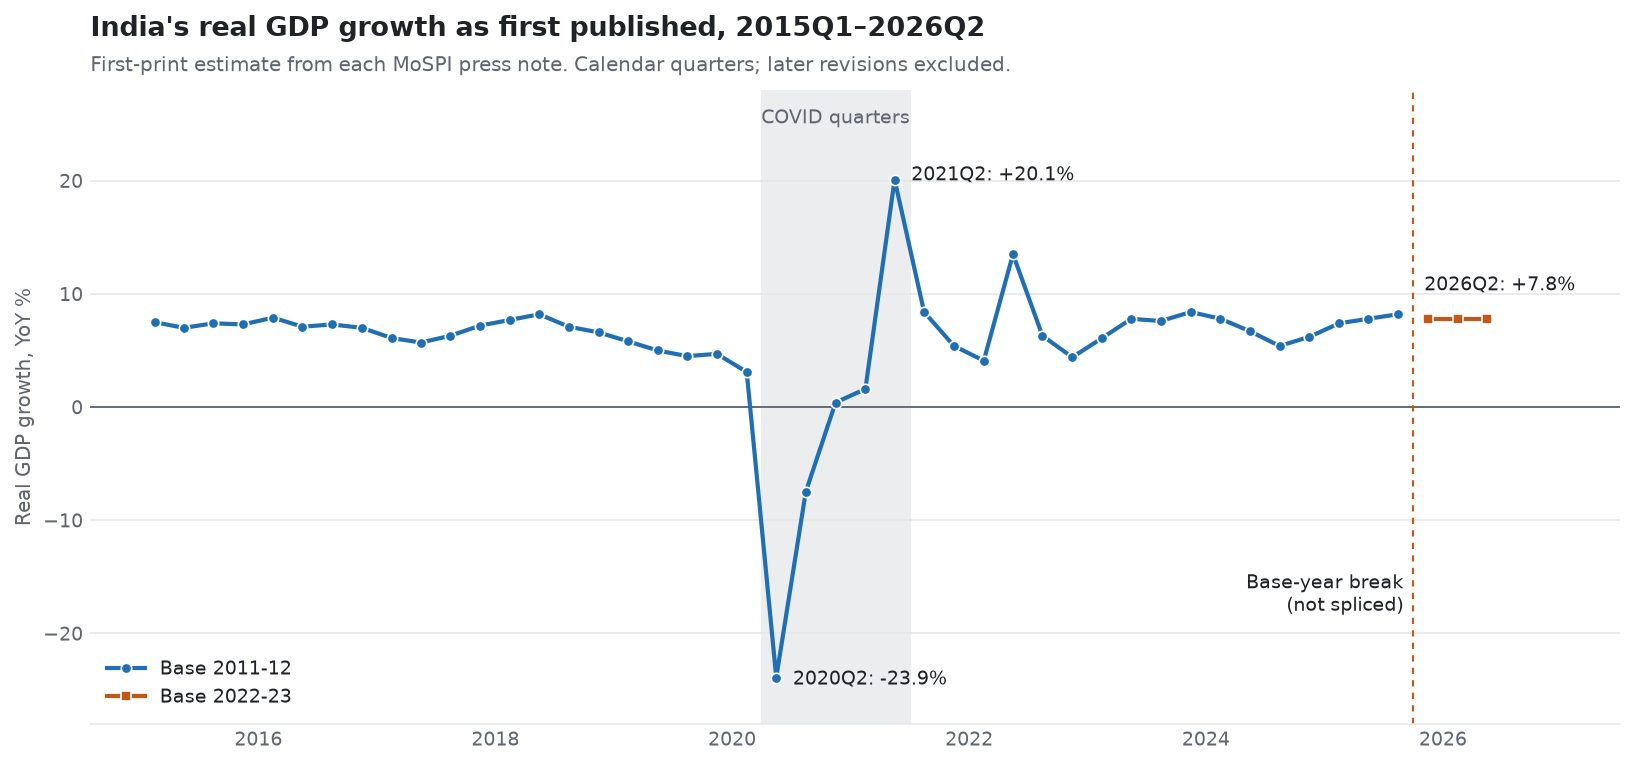

In [11]:
COLOR = {"2011-12": "#1F6FB2", "2022-23": "#C2571A"}
INK, MUTED, GRID = "#1F2328", "#5F6670", "#E6E7E9"

plot = raw.assign(x=pd.PeriodIndex(raw["quarter"], freq="Q").to_timestamp(how="start") + pd.Timedelta(days=45))
fig, ax = plt.subplots(figsize=(11, 5.2), dpi=150)
ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2021-07-01"), color="#ECEDEF", zorder=0)
ax.axhline(0, color=MUTED, lw=0.9, zorder=1)
for base, marker, label in (("2011-12", "o", "Base 2011-12"), ("2022-23", "s", "Base 2022-23")):
    part = plot[plot["base_year"] == base]
    ax.plot(part["x"], part["growth"], color=COLOR[base], lw=2, marker=marker, ms=5,
            mec="white", mew=0.8, label=label, zorder=3)

def label_point(q, text, dx, dy, ha="left"):
    point = plot.set_index("quarter").loc[q]
    ax.annotate(text, (point["x"], point["growth"]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va="center", color=INK, fontsize=9)
for q, dx, dy, ha in (("2020Q2", 8, -1, "left"), ("2021Q2", 8, 2, "left")):
    value = plot.set_index("quarter").at[q, "growth"]
    label_point(q, f"{q}: {value:+.1f}%", dx, dy, ha)
last = plot.iloc[-1]
label_point(last["quarter"], f"{last['quarter']}: {last['growth']:+.1f}%", -30, 16, "left")
ax.set_xlim(pd.Timestamp("2014-08-01"), pd.Timestamp("2027-07-01"))

ax.text(pd.Timestamp("2020-11-15"), 25.5, "COVID quarters", ha="center", va="center", color=MUTED, fontsize=9)
break_x = plot.loc[plot["base_year"] == "2022-23", "x"].iat[0] - pd.Timedelta(days=45)
ax.axvline(break_x, color=COLOR["2022-23"], lw=1, ls=(0, (3, 3)), zorder=2)
ax.text(break_x - pd.Timedelta(days=30), -18, "Base-year break\n(not spliced)", ha="right", color=INK, fontsize=9)

ax.set_ylim(-28, 28)
ax.set_ylabel("Real GDP growth, YoY %", color=MUTED, fontsize=9.5)
ax.set_title("India's real GDP growth as first published, 2015Q1–2026Q2", loc="left", color=INK, fontsize=13, fontweight="bold", pad=26)
ax.text(0, 1.03, "First-print estimate from each MoSPI press note. Calendar quarters; later revisions excluded.",
        transform=ax.transAxes, color=MUTED, fontsize=9.5)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0, labelsize=9)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=INK)
fig.tight_layout()
fig.savefig(REPORTS / "gdp_first_print.png", bbox_inches="tight", facecolor="white")
plt.show()

## Data gaps

**Missing values: none.** All 46 quarters from 2015Q1 to 2026Q2 have a value, a release date and a source URL, parsed from a downloaded PDF. No value was filled in from memory or from media reports.

**Where "first print" can't be fully proven.** The value is present in each case, but the release-day file could not be confirmed:

| Quarter | Issue | Evidence the value is sound |
|---|---|---|
| 2016Q4 | Only the file suffixed `r` can be retrieved. The unsuffixed original is gone from MoSPI and has no usable Wayback capture. | Embargo line is the original date (28 Feb 2017), and growth matches the levels. **No second copy to compare.** |
| 2019Q3 | The English file is labelled `_revised`, and what was revised is unknown. | The Hindi note has the same levels and growth rate. |
| 2021Q3 | Only the file suffixed `N` was found. | Embargo line is the original date (30 Nov 2021), and growth matches the levels. **No second copy to compare.** |

**Reissued notes, resolved.** For 2023Q3, 2023Q4 and 2024Q4, MoSPI's live file is a later reissue, so the notebook uses the release-day Wayback capture. Each reissue gives the same headline figure. PIB's corrigendum to the 29 Feb 2024 note describes changes to disposable-income rows in Statement 2A, not to quarterly GDP. That description comes from PIB's page, and the corrigendum PDF itself was not downloaded.

**Sources that aren't MoSPI's live site.** 2021Q1, 2025Q2 and 2025Q3 use PIB's copy of the note. The 2025Q2 and 2025Q3 copies were checked against archived MoSPI copies and match. 2021Q1 has no second copy.

**Not yet published.** 2026Q3 (Jul–Sep 2026) is excluded because it hasn't been released; the cell above prints the release date given in the latest note.

**⚠️ Base-year break: not a missing value, but it does limit modelling.**
- 43 quarters (2015Q1–2025Q3) are on a 2011-12 base and 3 quarters (2025Q4–2026Q2) are on a 2022-23 base.
- Over the 10 quarters from 2023Q2 to 2025Q3, the old-base first print differs from the new-base figure by 0.77 pp on average (from −1.3 to +1.2). That gap combines the rebasing with ordinary revisions, so it isn't a pure base effect.
- The average difference is only −0.09 pp, so the gap is **noise rather than a level shift**, and a simple level adjustment wouldn't remove it.
- MoSPI says the back series is expected by December 2026. It will be a revised series, not first prints, so it can't replace this column, though it could help check the break.
